In [121]:
# Install all required libraries
%pip install pandas numpy matplotlib seaborn wordcloud nltk scikit-learn kagglehub


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Email Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/shalmamuji/spam-email-classification

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re
import string
import nltk

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

nltk.download('stopwords')
nltk.download('wordnet')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Acer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Acer\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [123]:
from pathlib import Path
import kagglehub
import pandas as pd

# Download the dataset linked at the beginning of this notebook.
dataset_dir = Path(kagglehub.dataset_download("shalmamuji/spam-email-classification"))
csv_files = sorted(dataset_dir.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {dataset_dir}")

for csv_path in csv_files:
    candidate = pd.read_csv(csv_path, encoding="latin-1")
    if {'email', 'label'}.issubset(candidate.columns):
        df = candidate[['email', 'label']].rename(columns={'email': 'message'})
        break
else:
    raise ValueError("The downloaded dataset must contain a CSV with email and label columns.")

print("Dataset loaded:", csv_path.name)
print("Total emails:", len(df))
print("Dataset columns:", df.columns.tolist())


Dataset loaded: email_classification_dataset.csv
Total emails: 10000
Dataset columns: ['message', 'label']


In [124]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nClass distribution:")
print(df['label'].value_counts())

print("\nFirst 5 email records:")
print(df.head())

Dataset shape: (10000, 2)

Missing values:
message    0
label      0
dtype: int64

Duplicate records: 8223

Class distribution:
label
ham     8500
spam    1500
Name: count, dtype: int64

First 5 email records:
                                             message label
0  From: support@legitcompany.com\nSubject: Regar...   ham
1  From: noreply@softwareupdates.com\nSubject: We...   ham
2  From: noreply@softwareupdates.com\nSubject: Im...   ham
3  From: info@customerservice.co\nSubject: Team S...   ham
4  From: info@customerservice.co\nSubject: Team S...   ham


Average email length: 246.84
Average number of words: 37.1
Emails containing subject: 10000


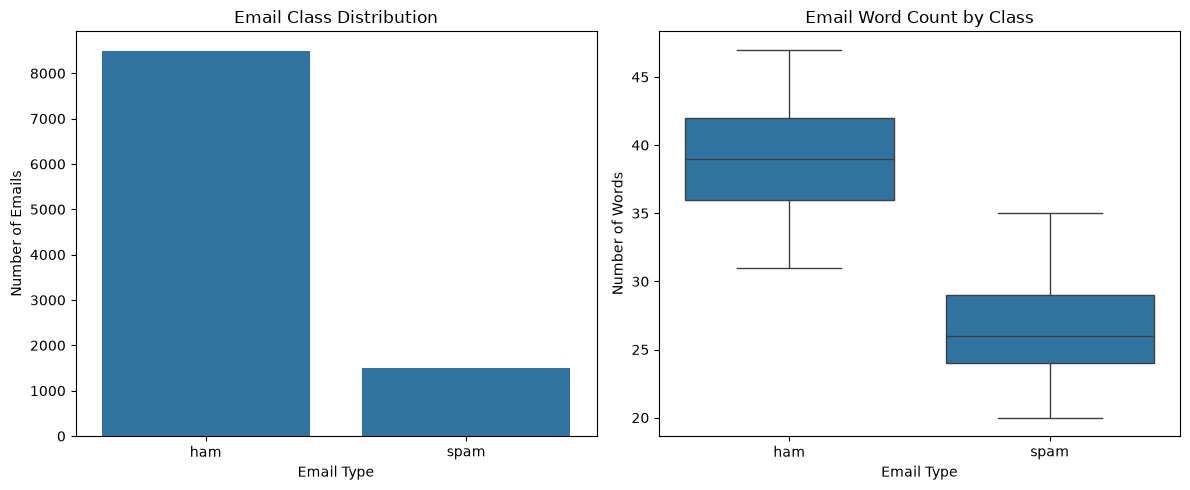

In [125]:
# Calculate basic email statistics
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['line_count'] = df['message'].str.count('\n') + 1

# Check whether emails contain a subject line
df['has_subject'] = df['message'].str.contains(
    r'subject:',
    case=False,
    regex=True
)

print("Average email length:", round(df['char_count'].mean(), 2))
print("Average number of words:", round(df['word_count'].mean(), 2))
print("Emails containing subject:", df['has_subject'].sum())

# Visualize the data
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='label', ax=ax[0])
ax[0].set_title("Email Class Distribution")
ax[0].set_xlabel("Email Type")
ax[0].set_ylabel("Number of Emails")

sns.boxplot(data=df, x='label', y='word_count', ax=ax[1])
ax[1].set_title("Email Word Count by Class")
ax[1].set_xlabel("Email Type")
ax[1].set_ylabel("Number of Words")

plt.tight_layout()
plt.show()

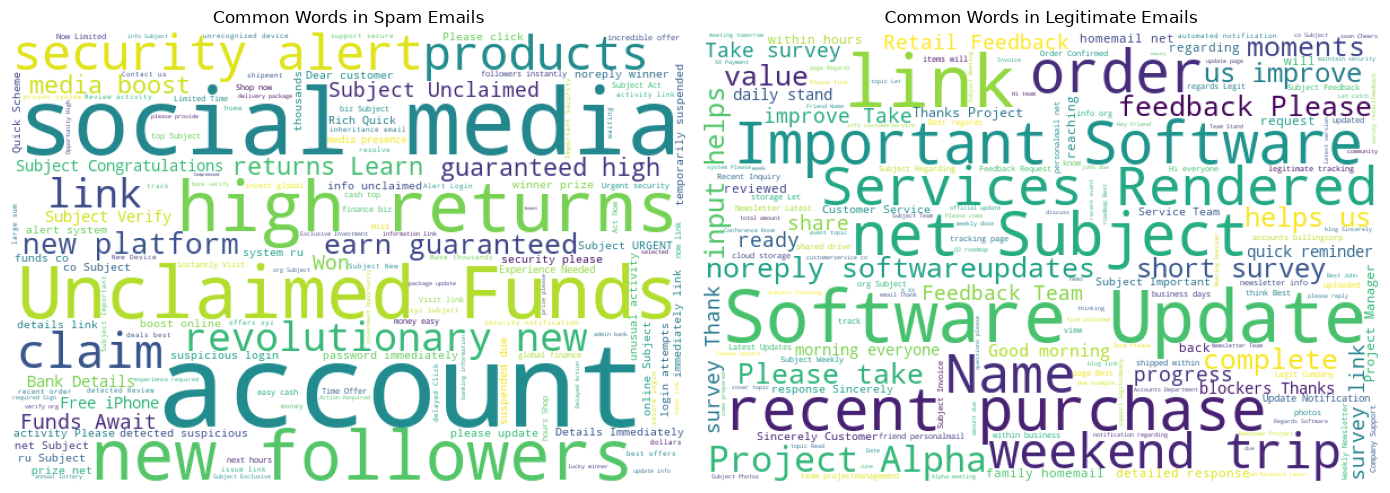

In [126]:
spam_text = ' '.join(df[df['label'] == 'spam']['message'])
ham_text = ' '.join(df[df['label'] == 'ham']['message'])

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
spam_cloud = WordCloud(
    width=600,
    height=400,
    background_color='white'
).generate(spam_text)

plt.imshow(spam_cloud)
plt.axis('off')
plt.title("Common Words in Spam Emails")

plt.subplot(1, 2, 2)
ham_cloud = WordCloud(
    width=600,
    height=400,
    background_color='white'
).generate(ham_text)

plt.imshow(ham_cloud)
plt.axis('off')
plt.title("Common Words in Legitimate Emails")

plt.tight_layout()
plt.show()

In [127]:
# Load English stopwords
stop_words = set(stopwords.words('english'))

# Create lemmatizer
lemm = WordNetLemmatizer()


def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove subject heading
    text = re.sub(r'\bsubject\s*:', ' ', text)

    # Remove numeric values
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Tokenize, remove stopwords and lemmatize
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join words back together
    text = ' '.join(tokens)

    # Normalize multiple spaces into one
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Remove duplicate emails
df = df.drop_duplicates()

# Remove rows with missing email or label
df = df.dropna(subset=['message', 'label'])

# Apply preprocessing
df['clean_message'] = df['message'].apply(clean_text)

# Convert labels to numerical values
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print("Preprocessing completed successfully!")
print("Remaining records:", len(df))

df[['label', 'clean_message']].head()

Preprocessing completed successfully!
Remaining records: 1777


,label,clean_message
0,0,regarding recent inquiry thank reaching regard...
1,0,weekly newsletter latest update please find at...
2,0,important software update notification thank o...
3,0,team standup please find attached invoice serv...
4,0,team standup here weekly dose news update comm...


In [128]:
X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", X_train.shape[0])
print("Testing emails:", X_test.shape[0])

Training emails: 1421
Testing emails: 356


In [129]:
pipeline = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        'svm',
        LinearSVC()
    )
])

pipeline.fit(X_train, y_train)

pred = pipeline.predict(X_test)

print("Model training completed.")
print("Test predictions generated:", len(pred))

Model training completed.
Test predictions generated: 356


In [130]:
print("===== EMAIL SPAM CLASSIFIER RESULTS =====")

print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1 Score :", round(f1_score(y_test, pred), 4))

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        pred,
        target_names=['Legitimate Email', 'Spam Email']
    )
)

===== EMAIL SPAM CLASSIFIER RESULTS =====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Detailed Classification Report:
                  precision    recall  f1-score   support

Legitimate Email       1.00      1.00      1.00       200
      Spam Email       1.00      1.00      1.00       156

        accuracy                           1.00       356
       macro avg       1.00      1.00      1.00       356
    weighted avg       1.00      1.00      1.00       356



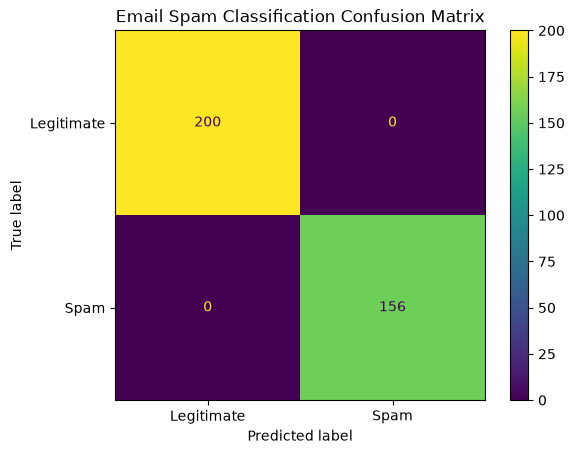

In [131]:
cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Spam']
)

disp.plot()
plt.title("Email Spam Classification Confusion Matrix")
plt.show()

In [132]:
param_grid = {
    'svm__C': [0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Hyperparameter tuning completed.")
print("Best SVM parameter:", grid.best_params_)
print("Best cross-validation score:", round(grid.best_score_, 4))

Hyperparameter tuning completed.
Best SVM parameter: {'svm__C': 0.1}
Best cross-validation score: 1.0


In [133]:
scores = cross_val_score(
    grid.best_estimator_,
    df['clean_message'],
    df['label'],
    cv=5
)

print("Cross-validation accuracy for each fold:")
print(np.round(scores, 4))

print("\nAverage cross-validation accuracy:",
      round(scores.mean(), 4))

print("Standard deviation:",
      round(scores.std(), 4))

Cross-validation accuracy for each fold:
[1. 1. 1. 1. 1.]

Average cross-validation accuracy: 1.0
Standard deviation: 0.0


In [ ]:
from textwrap import fill

def predict_spam(message):
    """Classify an email using the tuned SVM and training preprocessing."""
    cleaned_message = clean_text(message)
    prediction = grid.best_estimator_.predict([cleaned_message])[0]
    return "Spam Email" if prediction == 1 else "Legitimate Email"

def explain_prediction(message, top_n=5):
    """Show the strongest present TF-IDF features supporting the SVM label."""
    model = grid.best_estimator_
    vectorizer = model.named_steps['tfidf']
    svm = model.named_steps['svm']
    features = vectorizer.transform([clean_text(message)]).tocsr()
    prediction = svm.predict(features)[0]
    label = "spam" if prediction == 1 else "legitimate email"

    if features.nnz == 0:
        return ("No words matched the model's vocabulary after cleaning. "
                "This prediction comes from the model's baseline bias.")

    # A present feature's contribution is its TF-IDF value times its SVM weight.
    # Positive contributions favor classes_[1]; negative ones favor classes_[0].
    direction = 1 if prediction == svm.classes_[1] else -1
    feature_names = vectorizer.get_feature_names_out()
    supporting_terms = []
    for index, value in zip(features.indices, features.data):
        contribution = float(value * svm.coef_[0, index]) * direction
        if contribution > 0:
            supporting_terms.append((feature_names[index], contribution))
    supporting_terms.sort(key=lambda item: item[1], reverse=True)

    if not supporting_terms:
        return ("No individual words support this label. The model's baseline "
                "bias outweighs the word signals in this email.")

    terms = ", ".join(f"'{term}'" for term, _ in supporting_terms[:top_n])
    return (f"Strongest words or phrases pushing the prediction toward {label}: "
            f"{terms}. These are patterns learned from the training emails.")

examples = [
    ("Meeting reminder", "Legitimate Email",
     "Hi John, I wanted to remind you that our project meeting is scheduled for tomorrow at 3 PM. Please bring the updated report."),
    ("Cash prize offer", "Spam Email",
     "Congratulations! You have won a $1000 cash prize. Click the link now to claim your reward."),
    ("Project update", "Legitimate Email",
     "Hi team, the updated project report is attached. Please review the results before our meeting on Monday."),
    ("Assignment reminder", "Legitimate Email",
     "Dear students, please submit your machine learning assignment by Friday. Office hours are available tomorrow."),
    ("Lunch invitation", "Legitimate Email",
     "Hi Sara, would you like to have lunch together tomorrow? Let me know what time works for you."),
    ("Order confirmation", "Legitimate Email",
     "Thank you for your order. Your books have shipped and the delivery is scheduled for Tuesday."),
    ("Appointment reminder", "Legitimate Email",
     "This is a reminder of your scheduled appointment tomorrow at 10 AM. Please call the office if you need to reschedule."),
    ("Lottery scam", "Spam Email",
     "CONGRATULATIONS! Your email has won our million dollar lottery. Send your bank details now to collect your winnings!"),
    ("Account phishing", "Spam Email",
     "URGENT! Your bank account will be suspended today. Click http://verify-account.example and enter your password immediately."),
    ("Advance fee scam", "Spam Email",
     "You have been selected to receive a large inheritance. Pay a small processing fee today to release the funds."),
    ("Investment scam", "Spam Email",
     "Earn guaranteed profits with no risk! Double your money overnight. Send your deposit now to secure this exclusive opportunity."),
    ("Prize scam", "Spam Email",
     "You are our lucky winner! Claim your FREE smartphone now. Send your credit card information to pay the delivery fee."),
]

# Display each example in the same format.
print("EMAIL CLASSIFICATION EXAMPLES")
print("Compare the model prediction with the expected label for each sample.")

matches = 0
for number, (title, expected, message) in enumerate(examples, start=1):
    prediction = predict_spam(message)
    matches_expected = prediction == expected
    matches += matches_expected

    print("\n" + "=" * 72)
    print(f"EXAMPLE {number:02d}: {title}")
    print("-" * 72)
    print("Email text:")
    print(fill(message, width=72, initial_indent="  ", subsequent_indent="  "))
    print()
    print(f"  Expected label   : {expected}")
    print(f"  Model prediction : {prediction}")
    print("  Why this prediction:")
    print(fill(explain_prediction(message), width=72,
               initial_indent="    ", subsequent_indent="    "))
    print(f"  Result           : {'Matches expected label' if matches_expected else 'Does not match expected label'}")

print("\n" + "=" * 72)
print(f"SUMMARY: {matches} of {len(examples)} examples matched their expected labels.")
print("These sample results are separate from the test-set evaluation above.")
